In [5]:
import torch
import pandas as pd

In [6]:
tiles = torch.load("data/tiles_tensor_2016_AN_UTIG.pt")
metadata = pd.read_csv("data/tiles_metadata_2016_AN_UTIG.csv")

In [7]:
tiles.shape, metadata.shape

(torch.Size([705, 1, 336, 336]), (705, 14))

In [19]:
metadata

,survey_id,granule_id,x_idx,X,Y,LON,LAT,bed_elevation,surface_elevation,ice_thickness,partial_bed_reflect,srf_reflect,tile_along_track_span_m,tile_vertical_span_m
0,ER2HI2_2017024_TOT1_JKB2r_X19a_,ER2HI1B_2017024_TOT1_JKB2r_X19a_000,168,2.252190e+06,-1.000319e+06,113.948590,-67.59732,-832.53,489.93,1322.46,-58.86,-18.90,7154.872903,567.565173
1,ER2HI2_2017024_TOT1_JKB2r_X19a_,ER2HI1B_2017024_TOT1_JKB2r_X19a_000,504,2.252327e+06,-1.007471e+06,114.099075,-67.57039,-1048.94,490.98,1539.92,-63.53,-13.64,7136.538330,567.564866
2,ER2HI2_2017024_TOT1_JKB2r_X19a_,ER2HI1B_2017024_TOT1_JKB2r_X19a_000,840,2.252530e+06,-1.014620e+06,114.248505,-67.54278,-1121.98,467.22,1589.20,-62.71,-15.72,7169.676920,567.565019
3,ER2HI2_2017024_TOT1_JKB2r_X19a_,ER2HI1B_2017024_TOT1_JKB2r_X19a_000,1176,2.252524e+06,-1.021759e+06,114.399345,-67.51675,-912.73,398.34,1311.07,-58.42,-13.61,7132.055100,567.565019
4,ER2HI2_2017024_TOT1_JKB2r_X19a_,ER2HI1B_2017024_TOT1_JKB2r_X19a_000,1512,2.252602e+06,-1.028910e+06,114.549255,-67.48985,-733.43,396.43,1129.86,-59.38,-13.12,7133.057050,567.565019
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
700,ER2HI2_2017023_VFT_JKB2r_X14a_,ER2HI1B_2017023_VFT_JKB2r_X14a_000,2856,2.269254e+06,-9.506462e+05,112.730000,-67.63290,-557.20,816.56,1373.76,-53.05,-15.78,6431.130966,567.565173
701,ER2HI2_2017023_VFT_JKB2r_X14a_,ER2HI1B_2017023_VFT_JKB2r_X14a_000,3192,2.265972e+06,-9.562786e+05,112.880570,-67.64037,-862.75,717.95,1580.70,-52.83,-11.63,6688.008867,567.565173
702,ER2HI2_2017023_VFT_JKB2r_X14a_,ER2HI1B_2017023_VFT_JKB2r_X14a_000,3528,2.262582e+06,-9.621396e+05,113.037125,-67.64778,-772.76,726.47,1499.23,-62.06,-13.00,6720.163153,567.565019
703,ER2HI2_2017024_ICP8_JKB2r_F08T01a_,ER2HI1B_2017024_ICP8_JKB2r_F08T01a_002,504,2.269532e+06,-9.928031e+05,113.626900,-67.48348,-2007.52,371.15,2378.67,-78.12,-19.84,6918.465465,567.565173


In [17]:
top_mean = tiles[:, :, :100, :].mean(dim = (1, 2, 3))
metadata["ice_thickness"]

0      1322.46
1      1539.92
2      1589.20
3      1311.07
4      1129.86
        ...   
700    1373.76
701    1580.70
702    1499.23
703    2378.67
704    1812.30
Name: ice_thickness, Length: 705, dtype: float64

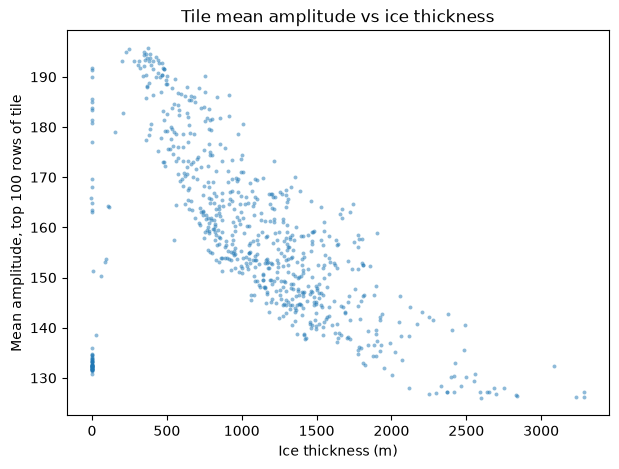

In [18]:
import matplotlib.pyplot as plt

x = metadata["ice_thickness"].values
y = top_mean.numpy()

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Ice thickness (m)")
ax.set_ylabel("Mean amplitude, top 100 rows of tile")
ax.set_title("Tile mean amplitude vs ice thickness")
plt.show()

# Note: Only interpret over 300m thickness because otherwise we have the surfac ein there

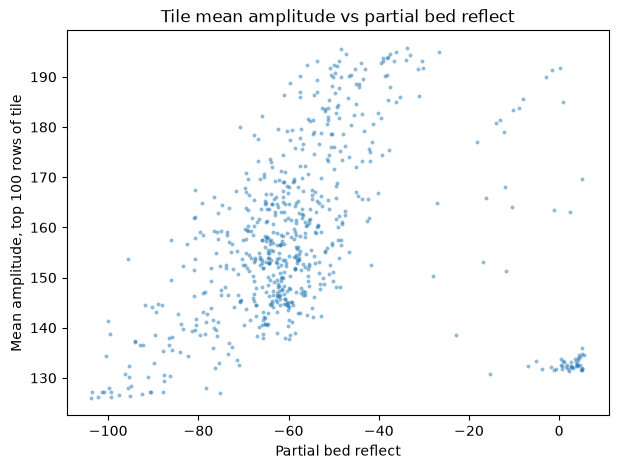

In [23]:
x = metadata["partial_bed_reflect"].values
y = top_mean.numpy()

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Partial bed reflect")
ax.set_ylabel("Mean amplitude, top 100 rows of tile")
ax.set_title("Tile mean amplitude vs partial bed reflect")
plt.show()

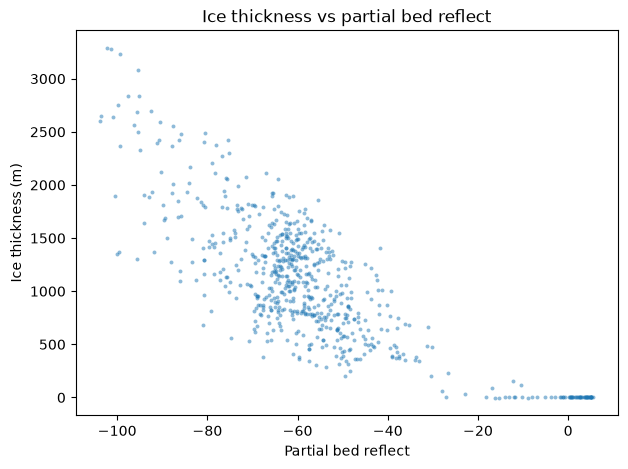

In [26]:
x = metadata["partial_bed_reflect"].values
y = metadata["ice_thickness"].values

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Partial bed reflect")
ax.set_ylabel("Ice thickness (m)")
ax.set_title("Ice thickness vs partial bed reflect")
plt.show()